# 06 - Acuerdo Inter-Juez

## Objetivo
- Evaluar la confiabilidad de las evaluaciones LLM-as-Judge
- Calcular Krippendorff's alpha entre jueces
- Analizar correlación entre pares de jueces (Spearman)
- Identificar casos de alta discordancia
- Evaluar adherencia a la rúbrica (distribución de scores + chi-cuadrado)
- Analizar sesgo sistemático entre jueces

In [66]:
import polars as pl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
import krippendorff
from pathlib import Path

plt.rcParams.update({"figure.dpi": 120, "figure.figsize": (12, 8)})

DATA_DIR = Path("..") / "part_i" 

In [67]:
df_judge = pl.read_csv(DATA_DIR / "final_judge_results.csv")
print(f"Datos del juez: {df_judge.shape}")
print(f"Columnas: {df_judge.columns}")

JUECES = sorted(df_judge["modelo_juez"].unique().to_list())
SISTEMAS = sorted(df_judge["sistema"].unique().to_list())
MODELOS_RESP = sorted(df_judge["modelo_respuesta"].unique().to_list())
RUBRICAS = ["score_respuesta_correcta", "score_precision_legal"]

print(f"\nJueces: {JUECES}")
print(f"Sistemas: {SISTEMAS}")
print(f"Modelos de respuesta: {MODELOS_RESP}")
print(f"\nPrimeras filas:")
display(df_judge.head(3))

Datos del juez: (2133, 9)
Columnas: ['numero_pregunta', 'numero_subpregunta', 'modelo_juez', 'sistema', 'modelo_respuesta', 'score_respuesta_correcta', 'reason_respuesta_correcta', 'score_precision_legal', 'reason_precision_legal']

Jueces: ['grok_4_1_fast_free', 'openrouter_deepseek_deepseek-chat-v3-1', 'openrouter_moonshotai_kimi-k2-0905']
Sistemas: ['llm_responses_agentic_rag', 'llm_responses_base_rag', 'llm_responses_no_rag']
Modelos de respuesta: ['gpt-5', 'gpt-5-mini', 'gpt-5-nano']

Primeras filas:


numero_pregunta,numero_subpregunta,modelo_juez,sistema,modelo_respuesta,score_respuesta_correcta,reason_respuesta_correcta,score_precision_legal,reason_precision_legal
i64,i64,str,str,str,f64,str,f64,str
1,1,"""grok_4_1_fast_free""","""llm_responses_no_rag""","""gpt-5-nano""",0.5,"""La respuesta es parcialmente c…",0.0,"""La respuesta no cita ningún ar…"
1,2,"""grok_4_1_fast_free""","""llm_responses_no_rag""","""gpt-5-nano""",1.0,"""La respuesta es completamente …",0.0,"""La respuesta no cita ningún ar…"
1,3,"""grok_4_1_fast_free""","""llm_responses_no_rag""","""gpt-5-nano""",1.0,"""La respuesta provista concluye…",0.0,"""La respuesta no cita ningún ar…"


## 1. Correlación de Spearman entre pares de jueces

Para cada rúbrica, pivotear los scores por juez y calcular Spearman entre cada par.

In [68]:
from itertools import combinations

for rubrica in RUBRICAS:
    print(f"\n{'='*60}")
    print(f"Rúbrica: {rubrica}")
    print(f"{'='*60}")

    # Pivotear: una columna por juez
    df_pivot = df_judge.select([
        "numero_pregunta", "numero_subpregunta", "sistema", "modelo_respuesta",
        "modelo_juez", rubrica
    ]).pivot(
        on="modelo_juez",
        index=["numero_pregunta", "numero_subpregunta", "sistema", "modelo_respuesta"],
        values=rubrica,
    )

    # Correlación entre pares
    for j1, j2 in combinations(JUECES, 2):
        if j1 in df_pivot.columns and j2 in df_pivot.columns:
            valid = df_pivot.select([j1, j2]).drop_nulls()
            if len(valid) > 2:
                vals1 = valid[j1].to_numpy()
                vals2 = valid[j2].to_numpy()
                rho, p = stats.spearmanr(vals1, vals2)
                print(f"  {j1[:25]} ↔ {j2[:25]}: ρ={rho:.4f}, p={p:.2e}, n={len(valid)}")


Rúbrica: score_respuesta_correcta
  grok_4_1_fast_free ↔ openrouter_deepseek_deeps: ρ=0.8226, p=4.98e-176, n=711
  grok_4_1_fast_free ↔ openrouter_moonshotai_kim: ρ=0.8438, p=8.58e-194, n=711
  openrouter_deepseek_deeps ↔ openrouter_moonshotai_kim: ρ=0.7937, p=3.47e-155, n=711

Rúbrica: score_precision_legal
  grok_4_1_fast_free ↔ openrouter_deepseek_deeps: ρ=0.7651, p=1.10e-137, n=711
  grok_4_1_fast_free ↔ openrouter_moonshotai_kim: ρ=0.8198, p=7.70e-174, n=711
  openrouter_deepseek_deeps ↔ openrouter_moonshotai_kim: ρ=0.7801, p=1.46e-146, n=711


## 2. Krippendorff's Alpha

**¿Qué es?**  
El **Alpha de Krippendorff** (α) es un coeficiente estadístico de acuerdo inter-anotadores desarrollado por Klaus Krippendorff. Mide en qué medida múltiples anotadores (aquí, los jueces LLM) asignan los mismos valores a las mismas unidades de análisis (preguntas/respuestas), corrigiendo el acuerdo esperado por azar.

Sus ventajas clave frente a otras métricas (Kappa de Cohen, ICC):
- Maneja **cualquier número de jueces** (no solo 2)
- Admite **datos faltantes** (missing values)
- Soporta distintos **niveles de medición**: nominal, ordinal, intervalo, razón
- Penaliza el desacuerdo de forma proporcional a la magnitud de la diferencia (en escala ordinal/intervalo)

**Interpretación (Krippendorff, 2004):**
| Valor de α        | Interpretación                                  |
| ----------------- | ----------------------------------------------- |
| α ≥ 0.800         | Acuerdo **bueno** — confiable para conclusiones |
| 0.667 ≤ α < 0.800 | Acuerdo **aceptable** — conclusiones tentativas |
| α < 0.667         | Acuerdo **insuficiente** — no confiable         |

> ⚠️ Krippendorff recomienda α ≥ 0.800 como umbral mínimo para datos en producción.

**Configuración en este análisis:**
- Nivel de medición: **ordinal** (scores 1–5 con orden pero sin distancias iguales garantizadas)
- Se calcula de forma global y por sistema de recuperación

---

### Qué hacer cuando el acuerdo es insuficiente (α < 0.667)

#### Implicancias

Un α bajo implica que los jueces **no están midiendo lo mismo**, o lo están midiendo de forma inconsistente. En el contexto de LLM-as-Judge esto puede deberse a:

- **Ambigüedad en la rúbrica**: los criterios de evaluación no están suficientemente especificados para guiar al juez hacia una interpretación única.
- **Sesgo de modelo**: distintos LLMs tienen priors diferentes sobre qué constituye una "buena respuesta" en dominio legal.
- **Dificultad intrínseca del ítem**: preguntas abiertas o de interpretación jurídica admiten múltiples respuestas correctas, haciendo que la escala 1–5 sea insuficiente.
- **Efectos de posición / formato**: diferencias en el prompt del juez pueden inducir tendencias sistemáticas distintas por modelo.

Si los scores no son confiables, **promediar los jueces introduce ruido en lugar de reducirlo**, lo que invalida comparaciones entre sistemas RAG.

#### Medidas recomendadas

| Estrategia | Descripción |
|---|---|
| **Revisar y clarificar la rúbrica** | Agregar ejemplos ancla (*anchor examples*) para cada nivel de score (1, 3, 5) para reducir ambigüedad de interpretación |
| **Seleccionar un único juez** | Si un juez muestra mayor correlación con el ground truth, usarlo como juez canónico en lugar de promediar |
| **Excluir ítems de alta discordancia** | Filtrar las preguntas donde `std_jueces > umbral` antes de calcular métricas agregadas |
| **Reformular el prompt del juez** | Estructurar el prompt con criterios más específicos (chain-of-thought + escala de Likert anclada) |
| **Aumentar el número de jueces** | Con más jueces independientes, el promedio es más robusto a valores atípicos individuales |
| **Reportar con cautela** | Si se mantiene α < 0.667, declararlo explícitamente como limitación en la tesis y presentar resultados por juez por separado |

> 📖 Ver también: Amidei et al. (2019) sobre fiabilidad de evaluaciones automáticas de NLG — [ACL Anthology](https://aclanthology.org/W19-2301/)

---

**Fuentes:**
- Krippendorff, K. (2004). *Content Analysis: An Introduction to Its Methodology* (2nd ed.). Sage. — [Google Books](https://books.google.com/books?id=q657o3M3C8cC)
- Artículo Wikipedia: [Krippendorff's alpha](https://en.wikipedia.org/wiki/Krippendorff%27s_alpha)
- Librería Python `krippendorff`: [PyPI](https://pypi.org/project/krippendorff/) | [GitHub](https://github.com/pln-fing-udelar/fast-krippendorff)
- Hayes, A. F., & Krippendorff, K. (2007). *Answering the Call for a Standard Reliability Measure for Coding Data*. Communication Methods and Measures, 1(1), 77–89. — [DOI](https://doi.org/10.1080/19312450709336664)


In [69]:
for rubrica in RUBRICAS:
    print(f"\n{'='*60}")
    print(f"Rúbrica: {rubrica}")
    print(f"{'='*60}")

    # Construir reliability data: filas=jueces, columnas=unidades
    df_pivot = df_judge.select([
        "numero_pregunta", "numero_subpregunta", "sistema", "modelo_respuesta",
        "modelo_juez", rubrica,
    ]).pivot(
        on="modelo_juez",
        index=["numero_pregunta", "numero_subpregunta", "sistema", "modelo_respuesta"],
        values=rubrica,
    )

    # Matriz de fiabilidad (jueces × unidades)
    judge_cols = [c for c in df_pivot.columns if c in JUECES]
    reliability_data = []
    for j in judge_cols:
        reliability_data.append(df_pivot[j].to_numpy().astype(float))
    reliability_matrix = np.array(reliability_data)

    # Alpha global
    alpha_ord = krippendorff.alpha(reliability_data=reliability_matrix, level_of_measurement="ordinal")
    alpha_nom = krippendorff.alpha(reliability_data=reliability_matrix, level_of_measurement="nominal")
    alpha_int = krippendorff.alpha(reliability_data=reliability_matrix, level_of_measurement="interval")

    print(f"  Alpha ordinal:  {alpha_ord:.4f}")
    print(f"  Alpha nominal:  {alpha_nom:.4f}")
    print(f"  Alpha interval: {alpha_int:.4f}")

    # Interpretación
    if alpha_ord >= 0.8:
        interp = "Bueno (α ≥ 0.8)"
    elif alpha_ord >= 0.667:
        interp = "Aceptable para conclusiones tentativas (0.667 ≤ α < 0.8)"
    else:
        interp = "Insuficiente (α < 0.667)"
    print(f"  Interpretación: {interp}")


Rúbrica: score_respuesta_correcta
  Alpha ordinal:  0.8078
  Alpha nominal:  0.4609
  Alpha interval: 0.8163
  Interpretación: Bueno (α ≥ 0.8)

Rúbrica: score_precision_legal
  Alpha ordinal:  0.7846
  Alpha nominal:  0.5093
  Alpha interval: 0.7714
  Interpretación: Aceptable para conclusiones tentativas (0.667 ≤ α < 0.8)


### 2.1 Alpha por sistema de recuperación

> **Hipótesis sobre mayor discordancia en `no_rag`:**  
> Es esperable que el acuerdo inter-juez sea **menor** para el sistema sin recuperación (`no_rag`) por varias razones:
>
> 1. **Ausencia de texto ancla**: En sistemas RAG, el fragmento recuperado actúa como referencia objetiva común para todos los jueces. Sin ese contexto, cada juez evalúa la respuesta en el vacío, aumentando la subjetividad.
> 2. **Mayor ambigüedad en las respuestas**: Las respuestas generadas sin RAG tienden a ser más genéricas, vagas o parcialmente correctas, lo que dificulta aplicar la rúbrica de forma consistente entre jueces.
> 3. **Dominio legal especializado**: En textos normativos, la precisión depende de artículos y redacciones exactas. Sin contexto recuperado, los jueces pueden discrepar sobre si una respuesta "correcta en espíritu" merece un score alto o bajo.
> 4. **Mayor variabilidad en el contenido evaluado**: Los sistemas RAG acotan las respuestas al fragmento recuperado; `no_rag` produce respuestas más heterogéneas, lo que amplía el espacio de interpretación del juez.


In [70]:
alpha_by_system = []

for rubrica in RUBRICAS:
    df_pivot_full = df_judge.select([
        "numero_pregunta", "numero_subpregunta", "sistema", "modelo_respuesta",
        "modelo_juez", rubrica,
    ]).pivot(
        on="modelo_juez",
        index=["numero_pregunta", "numero_subpregunta", "sistema", "modelo_respuesta"],
        values=rubrica,
    )

    judge_cols = [c for c in df_pivot_full.columns if c in JUECES]

    for sistema in SISTEMAS:
        subset = df_pivot_full.filter(pl.col("sistema") == sistema)
        if len(subset) > 5:
            rel_data = []
            for j in judge_cols:
                rel_data.append(subset[j].to_numpy().astype(float))
            rel_matrix = np.array(rel_data)

            alpha_val = krippendorff.alpha(reliability_data=rel_matrix, level_of_measurement="ordinal")
            alpha_by_system.append({
                "rubrica": rubrica,
                "sistema": sistema.replace("llm_responses_", ""),
                "alpha_ordinal": round(alpha_val, 4),
                "n": len(subset),
            })

df_alpha_sys = pl.DataFrame(alpha_by_system)
display(df_alpha_sys)

rubrica,sistema,alpha_ordinal,n
str,str,f64,i64
"""score_respuesta_correcta""","""agentic_rag""",0.8693,237
"""score_respuesta_correcta""","""base_rag""",0.8219,237
"""score_respuesta_correcta""","""no_rag""",0.6979,237
"""score_precision_legal""","""agentic_rag""",0.755,237
"""score_precision_legal""","""base_rag""",0.6389,237
"""score_precision_legal""","""no_rag""",0.6211,237


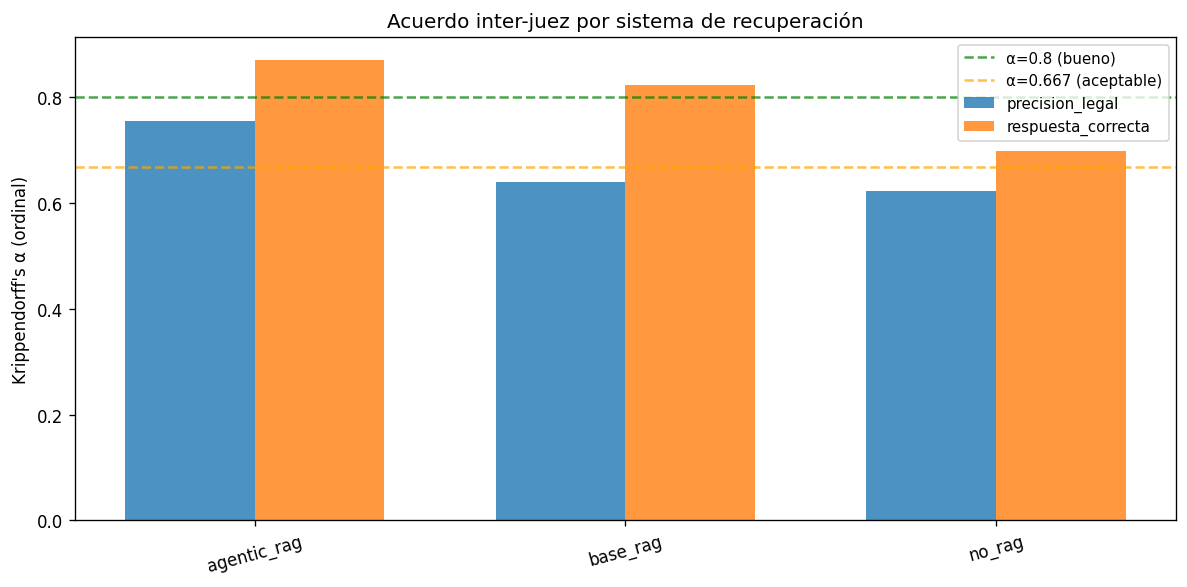

In [71]:
# Visualización del alpha por sistema
fig, ax = plt.subplots(figsize=(10, 5))

rubricas_labels = sorted(df_alpha_sys["rubrica"].unique().to_list())
sistemas_labels = sorted(df_alpha_sys["sistema"].unique().to_list())
x = np.arange(len(sistemas_labels))
width = 0.35

for i, rubrica in enumerate(rubricas_labels):
    subset = df_alpha_sys.filter(pl.col("rubrica") == rubrica).sort("sistema")
    alphas = subset["alpha_ordinal"].to_numpy()
    ax.bar(x + i * width, alphas, width, label=rubrica.replace("score_", ""), alpha=0.8)

ax.axhline(y=0.8, color="green", linestyle="--", alpha=0.7, label="α=0.8 (bueno)")
ax.axhline(y=0.667, color="orange", linestyle="--", alpha=0.7, label="α=0.667 (aceptable)")

ax.set_xticks(x + width / 2)
ax.set_xticklabels(sistemas_labels, rotation=15)
ax.set_ylabel("Krippendorff's α (ordinal)")
ax.set_title("Acuerdo inter-juez por sistema de recuperación")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

## 3. Análisis de discordancia

Identificar preguntas donde los jueces discrepan significativamente (alta varianza o rango entre jueces).

In [72]:
for rubrica in RUBRICAS:
    print(f"\n{'='*60}")
    print(f"Rúbrica: {rubrica} - Casos de alta discordancia")
    print(f"{'='*60}")

    df_pivot = df_judge.select([
        "numero_pregunta", "numero_subpregunta", "sistema", "modelo_respuesta",
        "modelo_juez", rubrica,
    ]).pivot(
        on="modelo_juez",
        index=["numero_pregunta", "numero_subpregunta", "sistema", "modelo_respuesta"],
        values=rubrica,
    )

    judge_cols = [c for c in df_pivot.columns if c in JUECES]

    # Calcular estadísticos de discordancia por fila
    # Usar numpy para std y rango
    scores_matrix = df_pivot.select(judge_cols).to_numpy().astype(float)
    std_vals = np.nanstd(scores_matrix, axis=1)
    range_vals = np.nanmax(scores_matrix, axis=1) - np.nanmin(scores_matrix, axis=1)

    df_discord = df_pivot.with_columns(
        pl.Series("std_jueces", std_vals),
        pl.Series("rango_jueces", range_vals),
    )

    # Top 10 más discordantes
    top_discord = df_discord.sort("std_jueces", descending=True).head(10)
    cols_to_show = ["numero_pregunta", "numero_subpregunta", "sistema", "modelo_respuesta"] + judge_cols + ["std_jueces", "rango_jueces"]
    display(top_discord.select(cols_to_show))

    # Distribución de la discordancia
    print(f"\nEstadísticos de discordancia (std entre jueces):")
    print(f"  Media: {np.nanmean(std_vals):.4f}")
    print(f"  Mediana: {np.nanmedian(std_vals):.4f}")
    print(f"  Max: {np.nanmax(std_vals):.4f}")
    print(f"  % con std > 1: {100 * np.mean(std_vals > 1):.1f}%")
    print(f"  % con rango >= 3: {100 * np.mean(range_vals >= 3):.1f}%")


Rúbrica: score_respuesta_correcta - Casos de alta discordancia


numero_pregunta,numero_subpregunta,sistema,modelo_respuesta,grok_4_1_fast_free,openrouter_deepseek_deepseek-chat-v3-1,openrouter_moonshotai_kimi-k2-0905,std_jueces,rango_jueces
i64,i64,str,str,f64,f64,f64,f64,f64
25,0,"""llm_responses_no_rag""","""gpt-5-nano""",0.0,0.0,1.0,0.471405,1.0
5,1,"""llm_responses_agentic_rag""","""gpt-5-nano""",0.0,1.0,0.0,0.471405,1.0
8,3,"""llm_responses_agentic_rag""","""gpt-5-nano""",0.0,1.0,1.0,0.471405,1.0
9,2,"""llm_responses_no_rag""","""gpt-5-mini""",0.0,1.0,0.0,0.471405,1.0
18,1,"""llm_responses_no_rag""","""gpt-5-mini""",0.0,0.0,1.0,0.471405,1.0
6,2,"""llm_responses_no_rag""","""gpt-5-nano""",0.25,1.0,0.0,0.424918,1.0
7,4,"""llm_responses_no_rag""","""gpt-5-mini""",0.25,1.0,0.0,0.424918,1.0
10,1,"""llm_responses_agentic_rag""","""gpt-5-nano""",0.0,0.9,0.0,0.424264,0.9
16,2,"""llm_responses_no_rag""","""gpt-5""",0.5,0.0,1.0,0.408248,1.0



Estadísticos de discordancia (std entre jueces):
  Media: 0.0875
  Mediana: 0.1179
  Max: 0.4714
  % con std > 1: 0.0%
  % con rango >= 3: 0.0%

Rúbrica: score_precision_legal - Casos de alta discordancia


numero_pregunta,numero_subpregunta,sistema,modelo_respuesta,grok_4_1_fast_free,openrouter_deepseek_deepseek-chat-v3-1,openrouter_moonshotai_kimi-k2-0905,std_jueces,rango_jueces
i64,i64,str,str,f64,f64,f64,f64,f64
1,2,"""llm_responses_no_rag""","""gpt-5-nano""",0.0,0.0,1.0,0.471405,1.0
7,4,"""llm_responses_agentic_rag""","""gpt-5-nano""",0.0,1.0,0.0,0.471405,1.0
9,1,"""llm_responses_agentic_rag""","""gpt-5-nano""",0.0,1.0,0.0,0.471405,1.0
12,3,"""llm_responses_agentic_rag""","""gpt-5-nano""",0.0,1.0,0.0,0.471405,1.0
13,2,"""llm_responses_agentic_rag""","""gpt-5-nano""",0.0,1.0,0.0,0.471405,1.0
7,2,"""llm_responses_no_rag""","""gpt-5-mini""",0.0,1.0,0.0,0.471405,1.0
3,3,"""llm_responses_no_rag""","""gpt-5""",1.0,0.0,1.0,0.471405,1.0
17,1,"""llm_responses_no_rag""","""gpt-5""",1.0,0.0,0.0,0.471405,1.0
25,0,"""llm_responses_no_rag""","""gpt-5""",1.0,0.0,0.0,0.471405,1.0



Estadísticos de discordancia (std entre jueces):
  Media: 0.1012
  Mediana: 0.0000
  Max: 0.4714
  % con std > 1: 0.0%
  % con rango >= 3: 0.0%


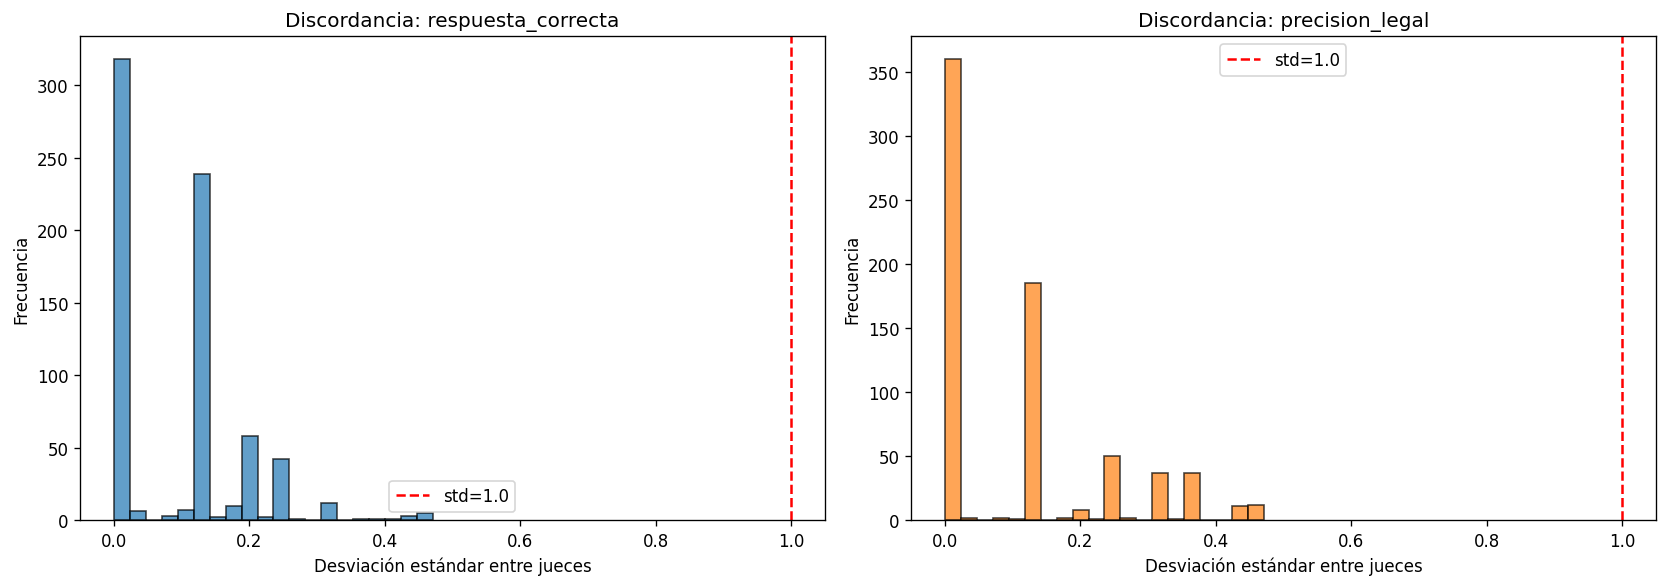

In [73]:
# Histograma de discordancia
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, rubrica in enumerate(RUBRICAS):
    df_pivot = df_judge.select([
        "numero_pregunta", "numero_subpregunta", "sistema", "modelo_respuesta",
        "modelo_juez", rubrica,
    ]).pivot(
        on="modelo_juez",
        index=["numero_pregunta", "numero_subpregunta", "sistema", "modelo_respuesta"],
        values=rubrica,
    )
    judge_cols = [c for c in df_pivot.columns if c in JUECES]
    scores_matrix = df_pivot.select(judge_cols).to_numpy().astype(float)
    std_vals = np.nanstd(scores_matrix, axis=1)

    ax = axes[i]
    ax.hist(std_vals, bins=20, edgecolor="black", alpha=0.7, color=["#1f77b4", "#ff7f0e"][i])
    ax.axvline(x=1.0, color="red", linestyle="--", label="std=1.0")
    ax.set_xlabel("Desviación estándar entre jueces")
    ax.set_ylabel("Frecuencia")
    ax.set_title(f"Discordancia: {rubrica.replace('score_', '')}")
    ax.legend()

plt.tight_layout()
plt.show()

## 4. Adherencia a la rúbrica

### 4.1 Distribución de scores por juez

In [74]:
for rubrica in RUBRICAS:
    print(f"\n{'='*60}")
    print(f"Distribución de scores - {rubrica}")
    print(f"{'='*60}")

    for juez in JUECES:
        scores = df_judge.filter(pl.col("modelo_juez") == juez)[rubrica].drop_nulls()
        print(f"\n  {juez}:")
        value_counts = scores.value_counts().sort("count", descending=True)
        display(value_counts)


Distribución de scores - score_respuesta_correcta

  grok_4_1_fast_free:


score_respuesta_correcta,count
f64,u32
1.0,244
0.5,187
0.0,120
0.75,85
0.25,74
0.9,1



  openrouter_deepseek_deepseek-chat-v3-1:


score_respuesta_correcta,count
f64,u32
1.0,319
0.5,128
0.25,101
0.0,98
0.75,29
…,…
0.95,3
0.6,2
0.85,2



  openrouter_moonshotai_kimi-k2-0905:


score_respuesta_correcta,count
f64,u32
1.0,239
0.75,171
0.0,116
0.5,114
0.25,71


... (2 outputs left out)


  openrouter_deepseek_deepseek-chat-v3-1:


score_precision_legal,count
f64,u32
0.0,259
1.0,173
0.25,141
0.75,120
0.9,9
0.5,7
0.8,1
0.85,1



  openrouter_moonshotai_kimi-k2-0905:


score_precision_legal,count
f64,u32
0.0,240
0.25,179
1.0,164
0.75,120
0.5,6
0.9,2


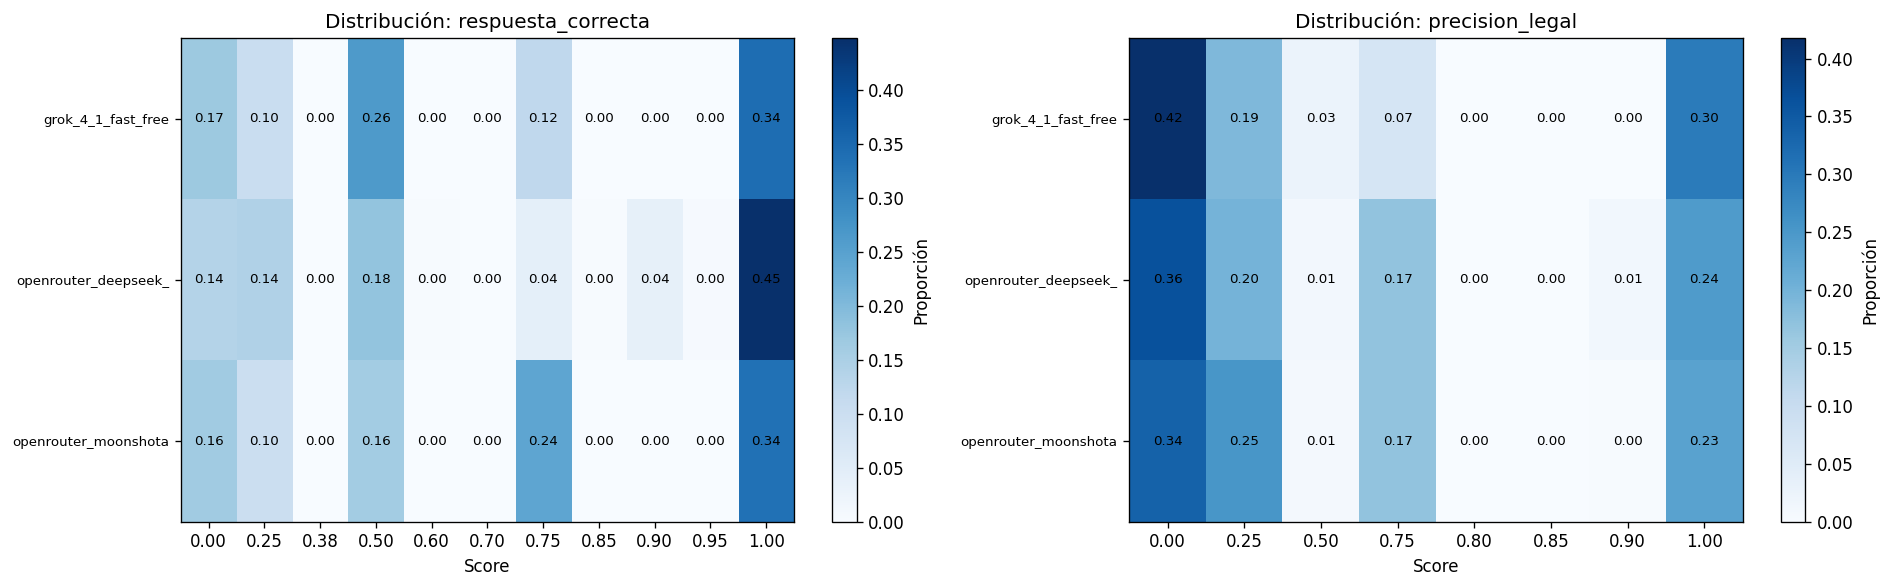

In [75]:

# Gráfico de distribución: heatmap de proporciones
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for idx, rubrica in enumerate(RUBRICAS):
    ax = axes[idx]
    juez_labels = [j[:20] for j in JUECES]
    all_scores = sorted(df_judge[rubrica].drop_nulls().unique().to_list())

    matrix_prop = np.zeros((len(JUECES), len(all_scores)))
    for i, juez in enumerate(JUECES):
        scores = df_judge.filter(pl.col("modelo_juez") == juez)[rubrica].drop_nulls()
        total = len(scores)
        for j, s in enumerate(all_scores):
            count = (scores == s).sum()
            matrix_prop[i, j] = count / total if total > 0 else 0

    im = ax.imshow(matrix_prop, cmap="Blues", aspect="auto")
    ax.set_xticks(range(len(all_scores)))
    ax.set_xticklabels([f"{s:.2f}" for s in all_scores])
    ax.set_yticks(range(len(JUECES)))
    ax.set_yticklabels(juez_labels, fontsize=8)
    ax.set_xlabel("Score")
    ax.set_title(f"Distribución: {rubrica.replace('score_', '')}")

    for i in range(len(JUECES)):
        for j in range(len(all_scores)):
            ax.text(j, i, f"{matrix_prop[i,j]:.2f}", ha="center", va="center", fontsize=8)

    plt.colorbar(im, ax=ax, label="Proporción")

plt.tight_layout()
plt.show()



### 4.1 - B - Distribución de scores por juez corregido

Se aplica la misma corrección de rúbrica que en `01_exploracion_descriptiva_correlacion.ipynb`:  
los valores fuera del conjunto válido **{0.0, 0.25, 0.5, 0.75, 1.0}** se redondean al valor más cercano (empates: el mayor).


In [76]:

RUBRICA_VALORES = [0.0, 0.25, 0.5, 0.75, 1.0]
_rubrica_arr = np.array(RUBRICA_VALORES)

def impute_to_rubrica(value: float) -> float:
    """Redondea al valor de rúbrica más cercano; empates se resuelven con el mayor."""
    dists = np.abs(_rubrica_arr - value)
    min_dist = dists.min()
    candidates = _rubrica_arr[dists == min_dist]
    return float(candidates.max())

df_judge_clean = df_judge.with_columns([
    pl.col(score_col)
      .map_elements(
          lambda v: impute_to_rubrica(v) if v not in RUBRICA_VALORES else v,
          return_dtype=pl.Float64,
      )
      .alias(score_col)
    for score_col in RUBRICAS
])

# Verificación
for score_col in RUBRICAS:
    n_restantes = df_judge_clean.filter(~pl.col(score_col).is_in(RUBRICA_VALORES)).height
    assert n_restantes == 0, f"Aún quedan {n_restantes} valores inválidos en {score_col}"

print("Imputación completada. Todos los valores respetan la rúbrica.")

# Mostrar cambios realizados
cambios_rows = []
for score_col in RUBRICAS:
    mask_invalidos = ~df_judge[score_col].is_in(RUBRICA_VALORES)
    if mask_invalidos.sum() > 0:
        original_vals = df_judge.filter(mask_invalidos).select(["modelo_juez", score_col]).rename({score_col: "original"})
        imputado_vals = df_judge_clean.filter(mask_invalidos).select([score_col]).rename({score_col: "imputado"})
        df_cambio = pl.concat([original_vals, imputado_vals], how="horizontal").with_columns(
            pl.lit(score_col).alias("metrica")
        )
        cambios_rows.append(df_cambio)

if cambios_rows:
    df_cambios = pl.concat(cambios_rows).unique(
        subset=["modelo_juez", "metrica", "original", "imputado"]
    ).sort(["modelo_juez", "metrica", "original"])
    print(f"\nResumen de imputaciones ({df_cambios.height} combinaciones únicas juez/metrica/valor):")
    display(df_cambios.select(["metrica", "modelo_juez", "original", "imputado"]))
else:
    print("No se encontraron valores fuera de rúbrica.")


Imputación completada. Todos los valores respetan la rúbrica.

Resumen de imputaciones (11 combinaciones únicas juez/metrica/valor):


metrica,modelo_juez,original,imputado
str,str,f64,f64
"""score_respuesta_correcta""","""grok_4_1_fast_free""",0.9,1.0
"""score_precision_legal""","""openrouter_deepseek_deepseek-c…",0.8,0.75
"""score_precision_legal""","""openrouter_deepseek_deepseek-c…",0.85,0.75
"""score_precision_legal""","""openrouter_deepseek_deepseek-c…",0.9,1.0
"""score_respuesta_correcta""","""openrouter_deepseek_deepseek-c…",0.375,0.5
…,…,…,…
"""score_respuesta_correcta""","""openrouter_deepseek_deepseek-c…",0.7,0.75
"""score_respuesta_correcta""","""openrouter_deepseek_deepseek-c…",0.85,0.75
"""score_respuesta_correcta""","""openrouter_deepseek_deepseek-c…",0.9,1.0


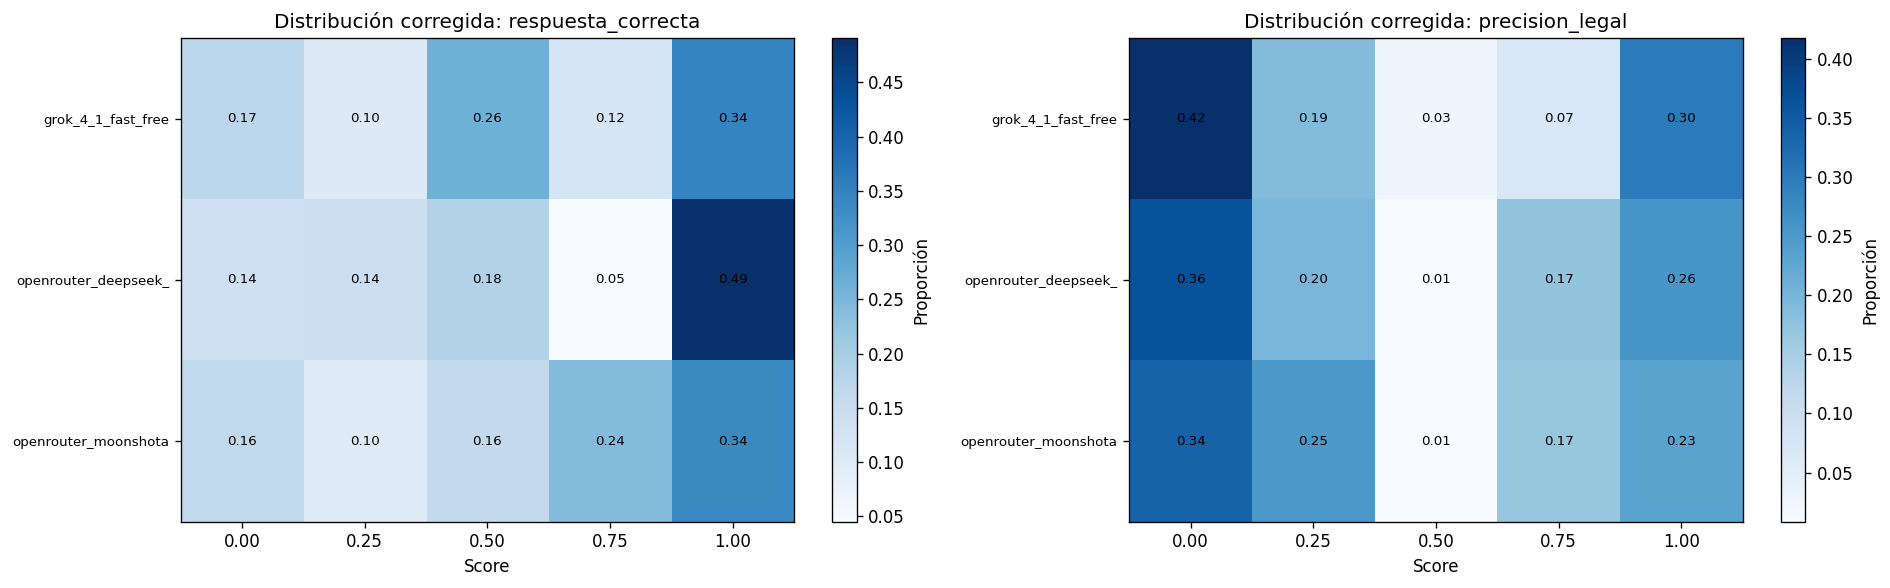

In [77]:

# Heatmap de proporciones — scores corregidos
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for idx, rubrica in enumerate(RUBRICAS):
    ax = axes[idx]
    juez_labels = [j[:20] for j in JUECES]
    all_scores = sorted(df_judge_clean[rubrica].drop_nulls().unique().to_list())

    matrix_prop = np.zeros((len(JUECES), len(all_scores)))
    for i, juez in enumerate(JUECES):
        scores = df_judge_clean.filter(pl.col("modelo_juez") == juez)[rubrica].drop_nulls()
        total = len(scores)
        for j, s in enumerate(all_scores):
            count = (scores == s).sum()
            matrix_prop[i, j] = count / total if total > 0 else 0

    im = ax.imshow(matrix_prop, cmap="Blues", aspect="auto")
    ax.set_xticks(range(len(all_scores)))
    ax.set_xticklabels([f"{s:.2f}" for s in all_scores])
    ax.set_yticks(range(len(JUECES)))
    ax.set_yticklabels(juez_labels, fontsize=8)
    ax.set_xlabel("Score")
    ax.set_title(f"Distribución corregida: {rubrica.replace('score_', '')}")

    for i in range(len(JUECES)):
        for j in range(len(all_scores)):
            ax.text(j, i, f"{matrix_prop[i,j]:.2f}", ha="center", va="center", fontsize=8)

    plt.colorbar(im, ax=ax, label="Proporción")

plt.tight_layout()
plt.show()


### 4.2 Test chi-cuadrado de homogeneidad

¿Los jueces distribuyen los scores de la misma manera?

**¿Qué prueba se usa y por qué?**

Se aplica el **test chi-cuadrado de homogeneidad** (`scipy.stats.chi2_contingency`) sobre la tabla de contingencia **jueces × valores de score**.

La elección de esta prueba se justifica por las siguientes razones:

1. **Naturaleza de los datos**: los scores son variables **categóricas ordinales** (0.0, 0.25, 0.5, 0.75, 1.0). No se asume que representen una variable continua con distribución normal, por lo que pruebas paramétricas como ANOVA no son apropiadas.

2. **Objetivo del contraste**: se quiere saber si la **distribución de frecuencias** de cada valor de score es la misma para todos los jueces, independientemente del ítem evaluado. Esto es exactamente lo que mide el test de homogeneidad: compara distribuciones entre grupos (aquí, los jueces).

3. **Estructura de los datos**: se construye una tabla de contingencia donde cada fila es un juez y cada columna es un posible valor de score. El estadístico $\chi^2$ cuantifica qué tanto se alejan las frecuencias observadas de las esperadas bajo la hipótesis de homogeneidad:

$$\chi^2 = \sum_{i,j} \frac{(O_{ij} - E_{ij})^2}{E_{ij}}$$

donde $O_{ij}$ es la frecuencia observada y $E_{ij}$ la frecuencia esperada si todos los jueces tuviesen la misma distribución.

**Hipótesis del contraste:**

- $H_0$: todos los jueces distribuyen los scores de la misma manera (homogeneidad).
- $H_1$: al menos un juez presenta una distribución de scores significativamente distinta.

**Interpretación:**

| Resultado | Conclusión |
|---|---|
| $p \geq 0.05$ | No hay evidencia para rechazar $H_0$; los jueces son homogéneos en su uso de la escala |
| $p < 0.05$ | Se rechaza $H_0$; los jueces presentan patrones de puntuación distintos (posible sesgo sistemático) |

> ⚠️ Un resultado significativo no identifica qué juez difiere del resto; para eso se complementa con el análisis de sesgos de la sección 5 y el heatmap de proporciones de la sección 4.1.

**Supuesto a verificar:**

- Las frecuencias esperadas $E_{ij}$ deben ser ≥ 5 en la mayoría de las celdas (regla práctica habitual). Si alguna categoría de score tiene muy pocas observaciones, se recomienda agrupar categorías adyacentes antes de aplicar el test.

In [78]:
for rubrica in RUBRICAS:
    print(f"\n{'='*60}")
    print(f"Chi-cuadrado de homogeneidad - {rubrica}")
    print(f"{'='*60}")

    all_scores = sorted(df_judge_clean[rubrica].drop_nulls().unique().to_list())

    # Tabla de contingencia: jueces × scores
    contingency = []
    for juez in JUECES:
        scores = df_judge_clean.filter(pl.col("modelo_juez") == juez)[rubrica].drop_nulls()
        row = []
        for s in all_scores:
            count = (scores == s).sum()
            row.append(count)
        contingency.append(row)

    contingency = np.array(contingency)
    chi2, p, dof, expected = stats.chi2_contingency(contingency)

    print(f"  χ² = {chi2:.4f}")
    print(f"  df = {dof}")
    print(f"  p  = {p:.6f}")
    print(f"  Significativo (p<0.05): {'SÍ' if p < 0.05 else 'NO'}")
    if p < 0.05:
        print("  → Los jueces NO distribuyen los scores de la misma manera")
    else:
        print("  → No hay evidencia de diferencia en la distribución de scores")

    # ── Verificación del supuesto: frecuencias esperadas ≥ 5 ──────────────────
    print(f"\n  Tabla de frecuencias esperadas (E_ij):")
    score_labels = [f"{s:.2f}" for s in all_scores]
    juez_labels  = [j[:25] for j in JUECES]

    df_expected = pd.DataFrame(
        expected.round(2),
        index=juez_labels,
        columns=score_labels,
    )
    df_expected.index.name = "juez \\ score"
    display(df_expected)

    n_cells_total = expected.size
    n_cells_low   = (expected < 5).sum()
    pct_low       = 100 * n_cells_low / n_cells_total
    min_expected  = expected.min()

    print(f"\n  Supuesto E_ij ≥ 5:")
    print(f"    Celdas totales      : {n_cells_total}")
    print(f"    Celdas con E_ij < 5 : {n_cells_low} ({pct_low:.1f}%)")
    print(f"    Mínimo E_ij         : {min_expected:.2f}")

    if pct_low == 0:
        print("    ✔ Supuesto cumplido — todas las frecuencias esperadas ≥ 5.")
    elif pct_low <= 20:
        print("    ⚠ Supuesto parcialmente cumplido (≤ 20% de celdas < 5).")
        print("      El resultado del test es aproximadamente válido.")
    else:
        print("    ✘ Supuesto NO cumplido (> 20% de celdas < 5).")
        print("      Considerar agrupar categorías de score adyacentes.")


Chi-cuadrado de homogeneidad - score_respuesta_correcta
  χ² = 159.4637
  df = 8
  p  = 0.000000
  Significativo (p<0.05): SÍ
  → Los jueces NO distribuyen los scores de la misma manera

  Tabla de frecuencias esperadas (E_ij):


,0.00,0.25,0.50,0.75,1.00
juez \ score,,,,,
grok_4_1_fast_free,111.33,82.0,144.0,96.0,277.67
openrouter_deepseek_deeps,111.33,82.0,144.0,96.0,277.67
openrouter_moonshotai_kim,111.33,82.0,144.0,96.0,277.67



  Supuesto E_ij ≥ 5:
    Celdas totales      : 15
    Celdas con E_ij < 5 : 0 (0.0%)
    Mínimo E_ij         : 82.00
    ✔ Supuesto cumplido — todas las frecuencias esperadas ≥ 5.

Chi-cuadrado de homogeneidad - score_precision_legal
  χ² = 61.7313
  df = 8
  p  = 0.000000
  Significativo (p<0.05): SÍ
  → Los jueces NO distribuyen los scores de la misma manera

  Tabla de frecuencias esperadas (E_ij):


,0.00,0.25,0.50,0.75,1.00
juez \ score,,,,,
grok_4_1_fast_free,265.33,151.33,10.33,97.67,186.33
openrouter_deepseek_deeps,265.33,151.33,10.33,97.67,186.33
openrouter_moonshotai_kim,265.33,151.33,10.33,97.67,186.33



  Supuesto E_ij ≥ 5:
    Celdas totales      : 15
    Celdas con E_ij < 5 : 0 (0.0%)
    Mínimo E_ij         : 10.33
    ✔ Supuesto cumplido — todas las frecuencias esperadas ≥ 5.


## 5. Sesgo sistemático entre jueces

El **sesgo sistemático** (o *leniency/severity bias*) ocurre cuando un juez tiende consistentemente a asignar scores más altos o más bajos que los demás, independientemente de la calidad real de la respuesta evaluada. A diferencia del desacuerdo aleatorio (capturado por Krippendorff's α), el sesgo sistemático es una desviación **direccional y estable**.

### Métricas analizadas

| Métrica | Descripción | Utilidad |
|---|---|---|
| **Media** | Promedio de scores asignados por el juez | Detecta lenidad/severidad global |
| **Mediana** | Valor central de la distribución | Robusta a outliers; comparar con media indica asimetría |
| **Desviación estándar (std)** | Dispersión absoluta de los scores | Indica si el juez discrimina entre respuestas buenas y malas |
| **Coef. de variación (CV = std/media)** | Dispersión relativa en % | Permite comparar la variabilidad entre jueces con distintas medias; un CV alto indica mayor discriminación relativa |

### Interpretación del sesgo

- **Media alta + std baja** → juez leniente y poco discriminador (*ceiling effect*)
- **Media baja + std baja** → juez severo y poco discriminador (*floor effect*)
- **CV alto** → el juez diferencia fuertemente entre respuestas buenas y malas, independientemente de su media
- **Diferencias de media > 0.15–0.20** entre jueces sugieren sesgos sistemáticos relevantes que deben reportarse como limitación

### Análisis por sistema

Se desagrega la media por sistema de recuperación para verificar si el sesgo de cada juez es **uniforme** (mismo patrón en todos los sistemas) o **diferencial** (varía según el contexto de recuperación). Un sesgo diferencial puede indicar que el juez responde de manera distinta al fragmento recuperado, lo que introduce un artefacto en la comparación entre sistemas RAG.


In [79]:
print("=== Medias de score por juez ===")
for rubrica in RUBRICAS:
    print(f"\n{rubrica}:")
    print(f"  {'Juez':<35} {'media':>8} {'mediana':>8} {'std':>8} {'CV (%)':>8}")
    print(f"  {'-'*35} {'-'*8} {'-'*8} {'-'*8} {'-'*8}")
    for juez in JUECES:
        scores = df_judge_clean.filter(pl.col("modelo_juez") == juez)[rubrica].drop_nulls().to_numpy()
        media = scores.mean()
        std = scores.std()
        cv = (std / media * 100) if media != 0 else float("nan")
        print(f"  {juez[:35]:<35} {media:>8.4f} {np.median(scores):>8.4f} {std:>8.4f} {cv:>7.1f}%")

=== Medias de score por juez ===

score_respuesta_correcta:
  Juez                                   media  mediana      std   CV (%)
  ----------------------------------- -------- -------- -------- --------
  grok_4_1_fast_free                    0.5918   0.5000   0.3659    61.8%
  openrouter_deepseek_deepseek-chat-v   0.6523   0.7500   0.3817    58.5%
  openrouter_moonshotai_kimi-k2-0905    0.6217   0.7500   0.3623    58.3%

score_precision_legal:
  Juez                                   media  mediana      std   CV (%)
  ----------------------------------- -------- -------- -------- --------
  grok_4_1_fast_free                    0.4103   0.2500   0.4323   105.3%
  openrouter_deepseek_deepseek-chat-v   0.4392   0.2500   0.4177    95.1%
  openrouter_moonshotai_kimi-k2-0905    0.4272   0.2500   0.4047    94.7%



=== Media de score por juez × sistema ===

score_respuesta_correcta:
  Juez                                  agentic_rag      base_rag        no_rag
  grok_4_1_fast_free                         0.6540        0.6108        0.5105
  openrouter_deepseek_deepseek-chat-v        0.6857        0.6814        0.5897
  openrouter_moonshotai_kimi-k2-0905         0.6751        0.6635        0.5264

score_precision_legal:
  Juez                                  agentic_rag      base_rag        no_rag
  grok_4_1_fast_free                         0.6055        0.5084        0.1171
  openrouter_deepseek_deepseek-chat-v        0.6287        0.5601        0.1287
  openrouter_moonshotai_kimi-k2-0905         0.5876        0.5369        0.1572

=== Rango inter-juez de la media por sistema (max − min) ===
(Valores altos indican sesgo diferencial según el sistema)

score_respuesta_correcta:
           agentic_rag: rango=0.0316  (medias: ['0.654', '0.686', '0.675'])
              base_rag: rango=0.0707  (med

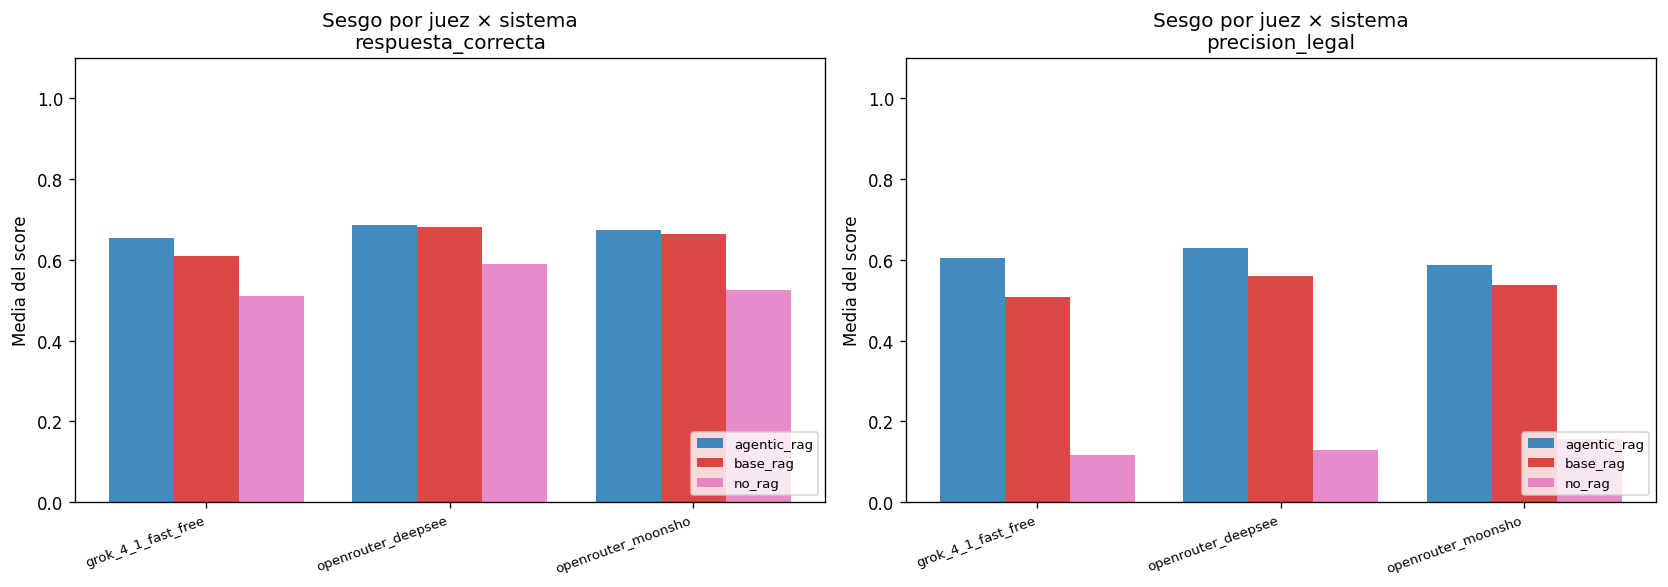

In [80]:
# ¿El sesgo varía según el sistema evaluado?
print("\n=== Media de score por juez × sistema ===")
for rubrica in RUBRICAS:
    print(f"\n{rubrica}:")
    print(f"  {'Juez':<35}", end="")
    for s in SISTEMAS:
        print(f"  {s.replace('llm_responses_', ''):>12}", end="")
    print()

    for juez in JUECES:
        print(f"  {juez[:35]:<35}", end="")
        for sistema in SISTEMAS:
            vals = df_judge_clean.filter(
                (pl.col("modelo_juez") == juez) & (pl.col("sistema") == sistema)
            )[rubrica].drop_nulls().to_numpy()
            if len(vals) > 0:
                print(f"  {vals.mean():>12.4f}", end="")
            else:
                print(f"  {'N/A':>12}", end="")
        print()

# -------------------------------------------------------------------
# Análisis de sesgo relativo: rango entre jueces por sistema
# -------------------------------------------------------------------
print("\n=== Rango inter-juez de la media por sistema (max − min) ===")
print("(Valores altos indican sesgo diferencial según el sistema)\n")
for rubrica in RUBRICAS:
    print(f"{rubrica}:")
    for sistema in SISTEMAS:
        medias = []
        for juez in JUECES:
            vals = df_judge_clean.filter(
                (pl.col("modelo_juez") == juez) & (pl.col("sistema") == sistema)
            )[rubrica].drop_nulls().to_numpy()
            if len(vals) > 0:
                medias.append(vals.mean())
        if len(medias) >= 2:
            rango = max(medias) - min(medias)
            print(f"  {sistema.replace('llm_responses_', ''):>20}: rango={rango:.4f}  (medias: {[f'{m:.3f}' for m in medias]})")

# -------------------------------------------------------------------
# Visualización: media por juez × sistema (barras agrupadas)
# -------------------------------------------------------------------
fig, axes = plt.subplots(1, len(RUBRICAS), figsize=(14, 5))
if len(RUBRICAS) == 1:
    axes = [axes]

sistemas_short = [s.replace("llm_responses_", "") for s in SISTEMAS]
x = np.arange(len(JUECES))
width = 0.8 / len(SISTEMAS)
colors = plt.cm.tab10(np.linspace(0, 0.6, len(SISTEMAS)))

for idx, rubrica in enumerate(RUBRICAS):
    ax = axes[idx]
    for i, (sistema, sistema_s) in enumerate(zip(SISTEMAS, sistemas_short)):
        medias = []
        for juez in JUECES:
            vals = df_judge_clean.filter(
                (pl.col("modelo_juez") == juez) & (pl.col("sistema") == sistema)
            )[rubrica].drop_nulls().to_numpy()
            medias.append(vals.mean() if len(vals) > 0 else np.nan)
        ax.bar(x + i * width, medias, width, label=sistema_s, alpha=0.85, color=colors[i])

    ax.set_xticks(x + width * (len(SISTEMAS) - 1) / 2)
    ax.set_xticklabels([j[:18] for j in JUECES], rotation=20, ha="right", fontsize=8)
    ax.set_ylabel("Media del score")
    ax.set_title(f"Sesgo por juez × sistema\n{rubrica.replace('score_', '')}")
    ax.legend(fontsize=8, loc="lower right")
    ax.set_ylim(0, 1.1)

plt.tight_layout()
plt.show()

## 6. Resumen

In [81]:
print("="*60)
print("RESUMEN DE ACUERDO INTER-JUEZ")
print("="*60)

print("\n1. Krippendorff's Alpha:")
for row in df_alpha_sys.iter_rows(named=True):
    alpha = row["alpha_ordinal"]
    if alpha >= 0.8:
        interp = "Bueno"
    elif alpha >= 0.667:
        interp = "Aceptable"
    else:
        interp = "Insuficiente"
    print(f"   [{row['sistema']}] {row['rubrica']}: α={alpha:.4f} ({interp})")

print("\n2. Implicaciones:")
print("   - Si α ≥ 0.8: Los jueces son confiables, se puede promediar.")
print("   - Si 0.667 ≤ α < 0.8: Conclusiones tentativas, reportar con cautela.")
print("   - Si α < 0.667: Considerar descartar evaluaciones poco fiables o usar un solo juez.")

RESUMEN DE ACUERDO INTER-JUEZ

1. Krippendorff's Alpha:
   [agentic_rag] score_respuesta_correcta: α=0.8693 (Bueno)
   [base_rag] score_respuesta_correcta: α=0.8219 (Bueno)
   [no_rag] score_respuesta_correcta: α=0.6979 (Aceptable)
   [agentic_rag] score_precision_legal: α=0.7550 (Aceptable)
   [base_rag] score_precision_legal: α=0.6389 (Insuficiente)
   [no_rag] score_precision_legal: α=0.6211 (Insuficiente)

2. Implicaciones:
   - Si α ≥ 0.8: Los jueces son confiables, se puede promediar.
   - Si 0.667 ≤ α < 0.8: Conclusiones tentativas, reportar con cautela.
   - Si α < 0.667: Considerar descartar evaluaciones poco fiables o usar un solo juez.


## 7. Conclusión final: cómo interpretar los resultados y decisiones metodológicas

### 7.1 Síntesis de hallazgos

Los tres jueces LLM muestran correlaciones de Spearman altas y significativas entre sí (ρ = 0.79–0.84 para `score_respuesta_correcta`; ρ = 0.77–0.82 para `score_precision_legal`), lo que indica un **ordenamiento relativo consistente** de las respuestas. Sin embargo, el test chi-cuadrado de homogeneidad rechaza la hipótesis nula para ambas rúbricas (p < 0.001), confirmando que existen **diferencias en los patrones de distribución de scores** entre jueces (sesgo sistemático leve).

El Alpha de Krippendorff ordinal revela una diferencia importante entre ambas métricas:

| Rúbrica                    | α global   | agentic_rag | base_rag | no_rag | Nivel de confiabilidad          |
| -------------------------- | ---------- | ----------- | -------- | ------ | ------------------------------- |
| `score_respuesta_correcta` | **0.8078** | 0.8693      | 0.8219   | 0.6979 | **Bueno** (α ≥ 0.8)             |
| `score_precision_legal`    | **0.7846** | 0.7550      | 0.6389   | 0.6211 | **Aceptable** (0.667 ≤ α < 0.8) |

---

### 7.2 ¿Debe eliminarse `score_precision_legal` y usar únicamente `score_respuesta_correcta`?

**Sí. Se recomienda usar exclusivamente `score_respuesta_correcta` para comparar estrategias de recuperación.** Las razones son:

1. **Confiabilidad insuficiente por sistema.** El α ordinal de `score_precision_legal` cae por debajo del umbral aceptable (α < 0.667) en dos de los tres sistemas: `base_rag` (α = 0.6389) y `no_rag` (α = 0.6211). Según Krippendorff (2004), esto significa que los jueces **no están midiendo el mismo constructo** de forma consistente en esas condiciones, lo que invalida promediar sus evaluaciones para comparar sistemas.

2. **Mayor variabilidad relativa.** El coeficiente de variación (CV) de `score_precision_legal` oscila entre 95–105%, frente al 58–62% de `score_respuesta_correcta`. Esto refleja que los jueces interpretan de manera mucho más heterogénea qué constituye "precisión legal" en una respuesta, lo que introduce ruido en lugar de señal.

3. **Ambigüedad conceptual inherente.** La noción de "precisión legal" es intrínsecamente más subjetiva que la de "respuesta correcta": un juez puede valorar la cita exacta de un artículo, otro la argumentación jurídica, y otro la conclusión normativa. Esta ambigüedad se refleja directamente en el menor acuerdo inter-juez y no puede resolverse sin reformular la rúbrica con anclas ejemplificadoras más específicas.

4. **`score_respuesta_correcta` es suficiente para el objetivo.** Con un α global de 0.8078 y α ≥ 0.82 en los sistemas RAG, esta métrica supera el umbral de confiabilidad recomendado por Krippendorff y permite hacer comparaciones válidas entre estrategias. Agregar una métrica poco confiable diluye la robustez de las conclusiones.

5. **Principio de parsimonia.** Incluir una segunda dimensión de evaluación solo se justifica si aporta información confiable e independiente. Dado que `score_precision_legal` tiene alta correlación con `score_respuesta_correcta` (ambas miden aspectos de calidad de la respuesta) pero menor confiabilidad, su inclusión agrega complejidad sin mejorar la capacidad de discriminar entre sistemas.

> **Nota:** esto no implica que la precisión legal carezca de importancia, sino que la rúbrica actual no logra que los jueces LLM la evalúen de forma reproducible. Una posible mejora futura sería rediseñar la rúbrica de precisión legal con ejemplos ancla específicos del dominio del Código de Minería.

---

### 7.3 ¿Qué estadístico tiene precedencia: el Alpha de Krippendorff o el test chi-cuadrado?

**El Alpha de Krippendorff tiene precedencia para decidir si las evaluaciones son confiables y si se puede comparar entre sistemas.** El test chi-cuadrado cumple un rol complementario pero subordinado. Las razones son:

1. **Naturaleza de la pregunta.** La pregunta central es *"¿podemos confiar en los scores de los jueces para comparar sistemas?"*, y esa es exactamente la pregunta que responde α. El chi-cuadrado responde una pregunta distinta: *"¿los jueces distribuyen los scores de forma idéntica?"* — lo cual es informativo pero no decisivo.

2. **Sensibilidad al tamaño muestral.** El test chi-cuadrado es una prueba de significación estadística que, con muestras suficientemente grandes, rechazará la hipótesis nula ante diferencias triviales. En este análisis, con cientos de observaciones por juez, incluso diferencias de media de 0.03–0.06 generan un p < 0.001. Eso no significa que el desacuerdo sea *relevante*, solo que es *detectable*.

3. **Magnitud vs. significación.** El α de Krippendorff mide la **magnitud del acuerdo** corrigiendo por azar, lo que permite establecer umbrales interpretables (α ≥ 0.8 = confiable). El chi-cuadrado solo provee una respuesta binaria (p < α → diferencia significativa), sin cuantificar si esa diferencia compromete la utilidad de las evaluaciones.

4. **Diseño para el propósito.** Krippendorff desarrolló α específicamente para evaluar la fiabilidad de anotadores en análisis de contenido, soportando múltiples anotadores, datos faltantes y escalas ordinales. El chi-cuadrado es una prueba genérica de asociación/homogeneidad que no fue diseñada para medir confiabilidad inter-anotadores.

5. **Uso correcto conjunto.** El test chi-cuadrado es útil como **diagnóstico complementario**: confirma que existen sesgos sistemáticos entre jueces (distribuciones no idénticas), lo cual explica por qué α no alcanza 1.0. Pero la decisión de considerar los scores como confiables o no se toma con α, no con χ².

**En resumen:** el Alpha de Krippendorff es el estadístico de decisión; el chi-cuadrado es un indicador de diagnóstico. Se reportan ambos, pero las conclusiones sobre la confiabilidad de las evaluaciones y la comparabilidad entre sistemas se fundamentan en α.